In [ ]:
pip install torch torchvision matplotlib pillow

In [ ]:
import torch
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

# Tekrarlanabilirlik için sabit seed
SEED = 42
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Cihaz:", device)

# MNIST normalizasyonu (eğitim setinin ortalaması ve standart sapması)
MEAN, STD = 0.1307, 0.3081
transform = transforms.Compose([
    transforms.ToTensor(),                 # [0,255] -> [0,1], şekil: 1x28x28
    transforms.Normalize((MEAN,), (STD,))  # normalizasyon
])

# 60.000 eğitim + 10.000 test görüntüsü
full_train = datasets.MNIST("./data", train=True,  download=True, transform=transform)
test_set   = datasets.MNIST("./data", train=False, download=True, transform=transform)

# Eğitim setini train (54.000) ve validation (6.000) olarak ayır
train_set, val_set = random_split(
    full_train, [54000, 6000],
    generator=torch.Generator().manual_seed(SEED)
)

BATCH_SIZE = 64
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_set,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_set,  batch_size=BATCH_SIZE, shuffle=False)

print(f"Train: {len(train_set)} | Validation: {len(val_set)} | Test: {len(test_set)}")

Cihaz: cpu
Train: 54000 | Validation: 6000 | Test: 10000


In [ ]:
import torch.nn as nn
import torch.optim as optim
import time

# ---------- Hiperparametreler (raporda belirtilecek) ----------
HIDDEN1 = 256
HIDDEN2 = 128
LR = 0.001
EPOCHS = 15
# BATCH_SIZE = 64 (Adım 1'de tanımlandı), Optimizer: Adam

# ---------- Model ----------
class MLP(nn.Module):
    def __init__(self, h1, h2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),             # 1x28x28 -> 784
            nn.Linear(784, h1),
            nn.ReLU(),
            nn.Linear(h1, h2),
            nn.ReLU(),
            nn.Linear(h2, 10)         # 10 sınıf, softmax loss içinde
        )

    def forward(self, x):
        return self.net(x)

model = MLP(HIDDEN1, HIDDEN2).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LR)
print(model)

# ---------- Yardımcı: bir veri kümesi üzerinde loss ve accuracy ----------
def evaluate(model, loader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += criterion(out, y).item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += x.size(0)
    return total_loss / total, correct / total

# ---------- Eğitim döngüsü ----------
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

start = time.time()
for epoch in range(EPOCHS):
    model.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()

    # Her epoch sonunda train ve validation ölçümü
    tr_loss, tr_acc = evaluate(model, train_loader)
    va_loss, va_acc = evaluate(model, val_loader)
    history["train_loss"].append(tr_loss)
    history["val_loss"].append(va_loss)
    history["train_acc"].append(tr_acc)
    history["val_acc"].append(va_acc)

    print(f"Epoch {epoch+1:2d}/{EPOCHS} | "
          f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f}")

train_time = time.time() - start
print(f"\nEğitim süresi: {train_time:.1f} saniye")

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Epoch  1/15 | train loss 0.1074 acc 0.9668 | val loss 0.1390 acc 0.9578
Epoch  2/15 | train loss 0.0639 acc 0.9796 | val loss 0.0960 acc 0.9708
Epoch  3/15 | train loss 0.0424 acc 0.9866 | val loss 0.0870 acc 0.9737
Epoch  4/15 | train loss 0.0380 acc 0.9878 | val loss 0.0813 acc 0.9733
Epoch  5/15 | train loss 0.0257 acc 0.9919 | val loss 0.0823 acc 0.9750
Epoch  6/15 | train loss 0.0216 acc 0.9933 | val loss 0.0809 acc 0.9765
Epoch  7/15 | train loss 0.0224 acc 0.9923 | val loss 0.0848 acc 0.9773
Epoch  8/15 | train loss 0.0177 acc 0.9940 | val loss 0.0920 acc 0.9763
Epoch  9/15 | train loss 0.0131 acc 0.9954 | val loss 0.0907 acc 0.9775
Epoch 10/15 | train loss 0.0281 acc 0.9909 | val loss 0.1366 

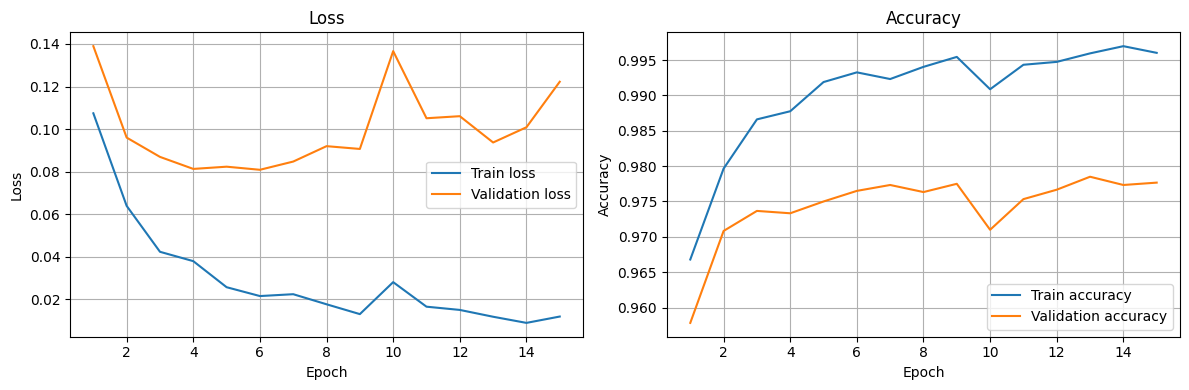

Test loss: 0.1098 | Test accuracy: 0.9779


In [ ]:
import matplotlib.pyplot as plt

epochs_range = range(1, EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss grafiği
axes[0].plot(epochs_range, history["train_loss"], label="Train loss")
axes[0].plot(epochs_range, history["val_loss"], label="Validation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Loss")
axes[0].legend()
axes[0].grid(True)

# Accuracy grafiği
axes[1].plot(epochs_range, history["train_acc"], label="Train accuracy")
axes[1].plot(epochs_range, history["val_acc"], label="Validation accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("deney1_egriler.png", dpi=150)   # README'de kullanacağız
plt.show()

# ---------- Test accuracy: SADECE BİR KEZ, en sonda ----------
test_loss, test_acc = evaluate(model, test_loader)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f}")

# Modeli kaydet (Adım 4'te el yazısı için lazım olacak)
torch.save(model.state_dict(), "mlp_deney1.pt")